# 03 · Modelado
**¿Se puede anticipar un éxito de ventas con lo que se sabe antes del lanzamiento?**

Los notebooks 01 y 02 dejaron tres ideas: el éxito (≥ 1 M de copias) es raro y concentrado, depende sobre todo del **publisher**, la **plataforma** y el **historial de la saga**, y el dataset está lleno de trampas que inflan cualquier modelo ingenuo. Este notebook construye un clasificador y lo evalúa de la forma más honesta que permite el dato.

| Sección | Qué responde |
|---|---|
| 1 | Qué se predice, para qué sirve y cómo se mide |
| 2 | Qué variables se pueden usar y cuáles no |
| 3 | Cómo se valida: de un AUC inflado a uno honesto |
| 4 | Qué información aporta cada bloque de variables |
| 5–6 | Modelos y baselines · ajuste fino |
| 7 | Prueba final en 2012–2014 |
| 8 | Prueba de estrés en 2015–2016 |
| 9 | Qué usa el modelo y dónde se equivoca |
| 10 | Conclusiones, límites y próximos pasos |

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd().parent                      # los notebooks se ejecutan desde notebooks/
sys.path.insert(0, str(RAIZ / "src"))
import estilo
import features as F
import limpieza as L
import modelado as M

warnings.filterwarnings("ignore", category=FutureWarning)
estilo.aplicar()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)

## 1. Planteamiento

**Pregunta.** Dado un lanzamiento (un juego en una plataforma) y **solo lo que se sabe antes de ver sus ventas**, ¿puede un modelo ordenar los lanzamientos de modo que los más prometedores concentren los éxitos?

**Uso de negocio imaginado.** Un equipo de catálogo o de marketing que tiene que repartir presupuesto entre muchos lanzamientos y quiere saber en cuáles apostar. No necesita una predicción exacta de ventas: necesita una **buena priorización**.

**Objetivo (`exito`).** 1 si el título vende ≥ 1 millón de copias en el mundo.

**Cómo se mide.** La *accuracy* no sirve: como la mayoría de los títulos no llega al millón, un modelo que diga siempre «no será un éxito» ya acierta ~88 %. Se usan métricas de ranking:

| Métrica | Qué mide | Referencia del azar |
|---|---|---|
| **AUC** | Probabilidad de que un éxito reciba mayor puntaje que un no-éxito | 0,5 |
| **PR-AUC** | Calidad de la lista priorizada cuando los éxitos son pocos | La tasa de éxito |
| **Precisión en el 10 % superior** (y su *lift*) | De los lanzamientos mejor puntuados, qué fracción son éxitos | La tasa de éxito |
| **Log-loss** | Calidad de las probabilidades (no solo del orden) | — |

In [2]:
limpio = pd.read_csv(L.PROCESSED, dtype={"anio": "Int64"})
base = F.agregar_historiales(F.preparar_base(limpio), rezago=F.REZAGO_MADUREZ)     # historiales con 1 año de rezago de madurez
assert not base.duplicated(["nombre", "plataforma", "anio"]).any()                  # clave única: permite cruzar resultados con la base

ventana = base[base["anio"].between(L.VENTANA_INICIO, L.VENTANA_FIN)]
print(f"Fichas analizables 1995–2014: {len(ventana):,} · tasa de éxito {ventana['exito'].mean():.1%} "
      f"→ «siempre no» acertaría el {1 - ventana['exito'].mean():.1%}")

por_anio = base[base["anio"].between(2006, 2016)].groupby("anio").agg(fichas=("exito", "size"), tasa_exito=("exito", "mean"))
por_anio["tasa_exito"] = (por_anio["tasa_exito"] * 100).round(1)
por_anio.T

Fichas analizables 1995–2014: 14,734 · tasa de éxito 12.2% → «siempre no» acertaría el 87.8%


anio,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
fichas,971.0,1178.0,1406.0,1424.0,1259.0,1139.0,656.0,546.0,582.0,614.0,344.0
tasa_exito,9.6,12.6,11.7,8.2,10.0,9.7,12.3,16.7,14.3,10.1,4.4


## 2. Variables: lo que se sabe antes del lanzamiento

| Bloque | Variables | ¿Por qué se conocen antes de vender? |
|---|---|---|
| Ficha | `plataforma`, `genero`, `publisher_grp` | Decisiones de lanzamiento. Los publishers con menos de 40 fichas se agrupan en «Otros» |
| Ciclo de la consola | `edad_plataforma` | Años desde que salió la consola |
| Distribución | `n_versiones` | En cuántas plataformas sale **el mismo año** (se planifica con antelación) |
| Franquicia | `fr_n_prev`, `fr_media_prev`, `fr_max_prev`, `fr_exito_prev` | Ventas de entregas anteriores de la saga |
| Publisher (opcional) | `pub_n_prev`, `pub_media_prev`, `pub_exito_prev` | Ventas de lanzamientos anteriores del publisher |

**Prohibidas:** `ventas_*` (el éxito se define con ellas), `rank_original` (es el objetivo ordenado) y el año calendario (casi no separa ventas y no se puede extrapolar fuera del rango de entrenamiento; la edad de la plataforma ya captura el momento del ciclo).

### El detalle delicado: los historiales no pueden mirar al futuro
El historial de una saga usa las **ventas finales** de sus entregas anteriores. Pero en el momento de lanzar el título del año *Y*, las ventas finales de lo lanzado en *Y − 1* todavía no existen (el dataset las trae acumuladas hasta 2016). Para no usar información que no se tendría, un título del año *Y* solo ve entregas **hasta *Y − 2*** (`rezago = 1`: un año completo para madurar). El costo es perder cobertura:

In [3]:
sin_rezago = F.historial_previo(F.preparar_base(limpio), "franquicia", "fr", rezago=0)
b0 = F.preparar_base(limpio)
dentro = b0["anio"].between(L.VENTANA_INICIO, L.VENTANA_FIN)
print(f"Fichas con alguna entrega previa de su saga:  sin rezago {(sin_rezago['fr_n_prev'] > 0)[dentro].mean():.1%}  ·  con rezago de 1 año {(ventana['fr_n_prev'] > 0).mean():.1%}")
print(f"Publishers distintos: {base['publisher_clave'].nunique()} → {base['publisher_grp'].nunique()} categorías tras agrupar\n")

ejemplo = ventana[ventana["franquicia"].eq("fifa") & ventana["plataforma"].eq("PS3") & ventana["anio"].between(2010, 2014)].sort_values("anio")
ejemplo[["nombre", "plataforma", "anio", "edad_plataforma", "n_versiones", "fr_n_prev", "fr_media_prev", "fr_max_prev", "fr_exito_prev", "exito"]].round(2).reset_index(drop=True)

Fichas con alguna entrega previa de su saga:  sin rezago 41.0%  ·  con rezago de 1 año 33.0%
Publishers distintos: 573 → 52 categorías tras agrupar



,nombre,plataforma,anio,edad_plataforma,n_versiones,fr_n_prev,fr_media_prev,fr_max_prev,fr_exito_prev,exito
0,FIFA Soccer 11,PS3,2010,4.0,7,49.0,0.52,1.65,0.31,1
1,FIFA 12,PS3,2011,5.0,7,56.0,0.56,1.65,0.34,1
2,FIFA Soccer 13,PS3,2012,6.0,8,63.0,0.60,1.81,0.37,1
3,FIFA 14,PS3,2013,7.0,8,70.0,0.62,2.04,0.36,1
4,FIFA 15,PS3,2014,8.0,8,79.0,0.63,2.22,0.34,1


> Lectura del ejemplo: *FIFA 14* (2013) solo ve las entregas hasta 2011, y *FIFA 15* (2014) hasta 2012. El historial refleja lo que **de verdad** se sabía al lanzar, no lo que se supo después.

## 3. Cómo se valida: de un AUC inflado a uno honesto
Un *split* aleatorio es la receta por defecto, pero aquí es optimista por tres motivos que ya se vieron en los notebooks anteriores:

1. **Mezcla de épocas**: se entrena con juegos de 2013 para «predecir» uno de 2008.
2. **Fichas hermanas**: la versión de PS3 cae en entrenamiento y la de Xbox 360 del mismo juego en prueba (47 % de las fichas tienen hermanas).
3. **Mirada al futuro** en los historiales (sin rezago).

El protocolo del proyecto es **walk-forward**: para evaluar el año *T* se entrena con todo lo anterior (desde 1995) y se predice *T*; así se imita el uso real. La siguiente «escalera» mide cuánto optimismo añade cada atajo, con **el mismo modelo y las mismas variables** en cada peldaño; solo cambia el protocolo (filas de 2006–2014).

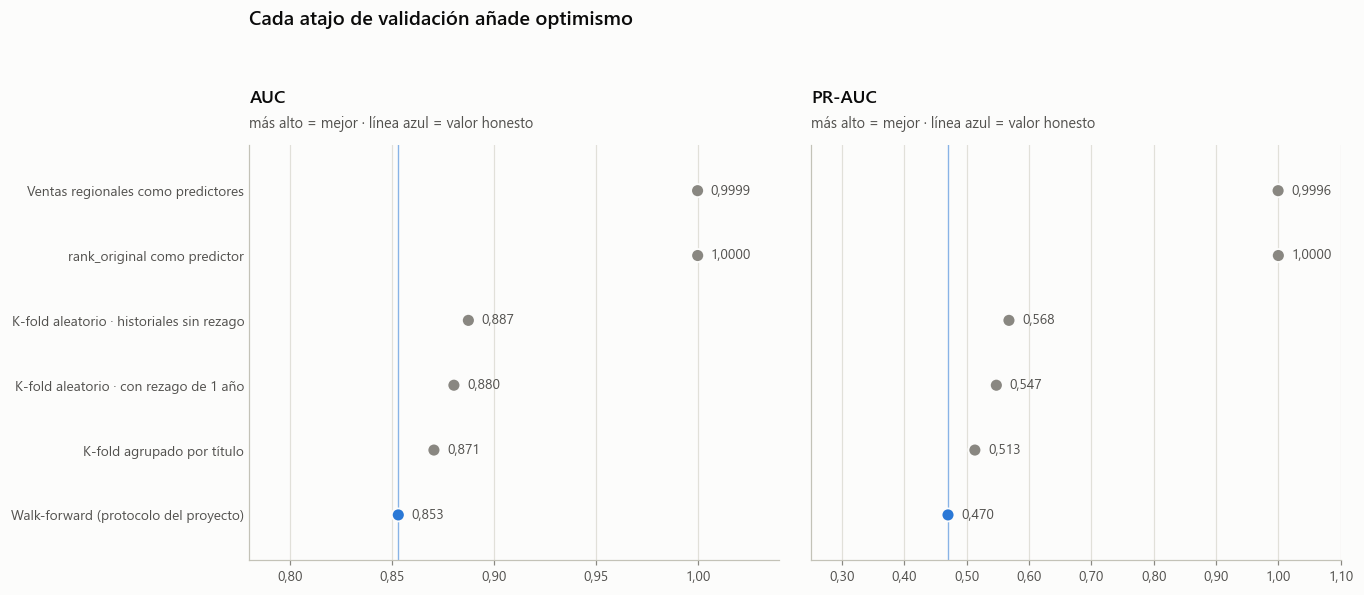

,protocolo,auc,pr_auc
0,Ventas regionales como predictores,0.9999,0.9996
1,rank_original como predictor,1.0000,1.0000
2,K-fold aleatorio · historiales sin rezago,0.8874,0.5677
3,K-fold aleatorio · con rezago de 1 año,0.8803,0.5475
4,K-fold agrupado por título,0.8705,0.5130
5,Walk-forward (protocolo del proyecto),0.8530,0.4699


In [4]:
cat_e, num_e = F.BLOQUES["E. + Historial del publisher"]                 # todas las variables, solo para esta comparación
base_sin_rezago = F.agregar_historiales(F.preparar_base(limpio), rezago=0)
filas_cv = lambda b: b[b["anio"].between(2006, 2014)].reset_index(drop=True)
b1, b0r = filas_cv(base), filas_cv(base_sin_rezago)
auc_pr = lambda r: (roc_auc_score(r["y"], r["p"]), average_precision_score(r["y"], r["p"]))

escalera = []
for nombre, columnas in [("Ventas regionales como predictores", L.VENTAS_REGIONALES), ("rank_original como predictor", ["rank_original"])]:
    p = np.zeros(len(b1))
    for tr, te in KFold(5, shuffle=True, random_state=0).split(b1):
        modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(b1.loc[tr, columnas], b1.loc[tr, "exito"])
        p[te] = modelo.predict_proba(b1.loc[te, columnas])[:, 1]
    escalera.append((nombre, roc_auc_score(b1["exito"], p), average_precision_score(b1["exito"], p)))

escalera.append(("K-fold aleatorio · historiales sin rezago", *auc_pr(M.validacion_cruzada(b0r, M.hgb, cat_e, num_e))))
escalera.append(("K-fold aleatorio · con rezago de 1 año", *auc_pr(M.validacion_cruzada(b1, M.hgb, cat_e, num_e))))
escalera.append(("K-fold agrupado por título", *auc_pr(M.validacion_cruzada(b1, M.hgb, cat_e, num_e, grupos="nombre"))))
escalera.append(("Walk-forward (protocolo del proyecto)", *auc_pr(M.recorrer_anios(base, M.hgb, cat_e, num_e, range(2006, 2015)))))
esc = pd.DataFrame(escalera, columns=["protocolo", "auc", "pr_auc"])

fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.9), sharey=True, gridspec_kw={"wspace": 0.06})
y = np.arange(len(esc))[::-1]
colores = [estilo.APAGADO] * (len(esc) - 1) + [estilo.AZUL]
for ax, col, titulo, lim in [(axes[0], "auc", "AUC", (0.78, 1.04)), (axes[1], "pr_auc", "PR-AUC", (0.25, 1.1))]:
    ax.axvline(esc[col].iloc[-1], color=estilo.AZUL, lw=0.9, alpha=0.55, zorder=2)
    ax.scatter(esc[col], y, s=72, color=colores, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4)
    for yi, v in zip(y, esc[col]):
        ax.text(v + (lim[1] - lim[0]) * 0.025, yi, estilo.num(v, 4 if 0.999 < v < 1 else 3), va="center", ha="left", fontsize=9, color=estilo.TINTA_2)
    ax.set_xlim(*lim)
    ax.set_ylim(-0.7, len(esc) - 0.3)
    estilo.rejilla(ax, "x")
    ax.xaxis.set_major_formatter(estilo.formato_eje(2))
    estilo.titular(ax, titulo, "más alto = mejor · línea azul = valor honesto")
axes[0].set_yticks(y, esc["protocolo"])
for ax in axes:
    ax.tick_params(axis="y", length=0)
fig.suptitle("Cada atajo de validación añade optimismo", x=0.125, y=1.13, ha="left", fontsize=13, fontweight="600", color=estilo.TINTA)
estilo.guardar(fig, "fig13_escalera_de_optimismo.png")
plt.show()
esc.round(4)

> **Hallazgo.** El optimismo se acumula peldaño a peldaño.
>
> - Las dos variables prohibidas dan un AUC de **1,000** sin aprender nada: el éxito *se define* con las ventas regionales y `rank_original` *es* las ventas ordenadas.
> - Entre los protocolos legítimos, el *K-fold* aleatorio con historiales sin rezago marca 0,887. **Quitar la mirada al futuro** (rezago) lo baja a 0,880; **agrupar por título**, para que las versiones de un mismo juego no crucen entrenamiento y prueba, a 0,871; y **respetar el tiempo** (walk-forward) a **0,853**.
> - El PR-AUC, más sensible, cae de 0,568 a 0,470.
>
> Entre el protocolo ingenuo y el honesto hay **+0,034 de AUC y +0,098 de PR-AUC que son puro optimismo**, no capacidad del modelo. De aquí en adelante todas las cifras se miden con walk-forward.

## 4. ¿Qué información aporta cada bloque de variables?
Los bloques se agregan uno a uno (de A a E) y se mide cada paso con **walk-forward sobre 2006–2011** (6 años de prueba; entrenamiento desde 1995 hasta el año anterior). El 2012–2014 se reserva para la prueba final.

**Regla fijada antes de mirar los resultados:** un bloque se conserva solo si sube el AUC medio al menos **0,005** respecto al anterior. Así el modelo final no incluye variables que no se ganan su lugar.

In [5]:
SEL = range(2006, 2012)                                                  # años de selección (walk-forward)
filas = []
for nombre, (cat, num) in F.BLOQUES.items():
    res = M.recorrer_anios(base, M.hgb, cat, num, SEL)
    media, desv = M.promedio_de_folds(res)
    filas.append({"bloque": nombre, "auc": media["auc"], "auc_sd": desv["auc"], "pr_auc": media["pr_auc"], "pr_sd": desv["pr_auc"],
                  "log_loss": media["log_loss"], "lift_top10": media["lift_top10"]})
abl = pd.DataFrame(filas)
abl["mejora_auc"] = abl["auc"].diff()

# se conserva el último bloque de la cadena mientras cada paso cumpla la regla
bloque_final = abl["bloque"].iloc[0]
for i in range(1, len(abl)):
    if abl.loc[i, "mejora_auc"] >= F.MEJORA_MINIMA_AUC:
        bloque_final = abl.loc[i, "bloque"]
    else:
        break
abl["se_conserva"] = abl["bloque"].map(lambda b: list(F.BLOQUES).index(b) <= list(F.BLOQUES).index(bloque_final))
CAT, NUM = F.BLOQUES[bloque_final]
print(f"Bloque final según la regla (mejora ≥ {F.MEJORA_MINIMA_AUC}): {bloque_final}")
print(f"Variables: {CAT + NUM}\n")
abl.round(4)

Bloque final según la regla (mejora ≥ 0.005): D. + Historial de franquicia
Variables: ['plataforma', 'genero', 'publisher_grp', 'edad_plataforma', 'n_versiones', 'fr_n_prev', 'fr_media_prev', 'fr_max_prev', 'fr_exito_prev']



,bloque,auc,auc_sd,pr_auc,pr_sd,log_loss,lift_top10,mejora_auc,se_conserva
0,A. Plataforma y genero,0.6873,0.0533,0.1972,0.0386,0.3175,2.2301,NaN,True
1,B. + Publisher,0.8056,0.0497,0.3424,0.0558,0.2758,3.5469,0.1184,True
2,C. + Edad de plataforma y versiones,0.8135,0.0440,0.3481,0.0607,0.2711,3.6396,0.0079,True
3,D. + Historial de franquicia,0.8379,0.0385,0.4407,0.0358,0.2548,4.2759,0.0244,True
4,E. + Historial del publisher,0.8392,0.0396,0.4389,0.0496,0.2536,4.3319,0.0013,False


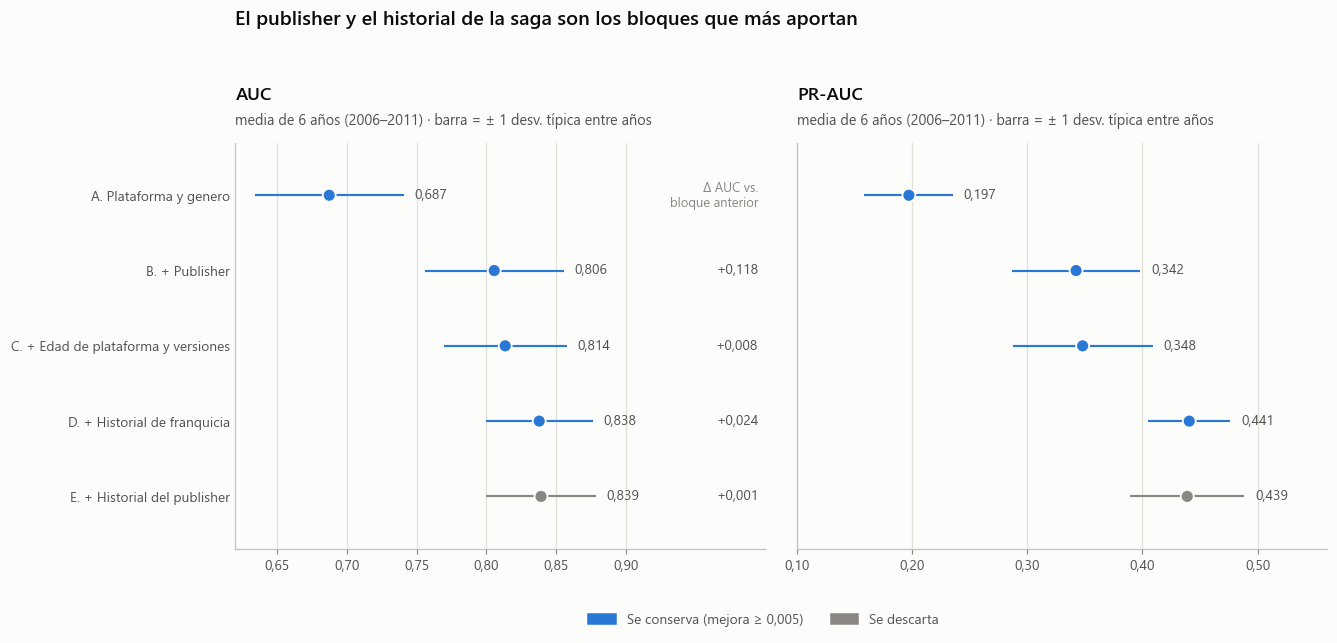

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8), sharey=True, gridspec_kw={"wspace": 0.06})
y = np.arange(len(abl))[::-1]
colores = np.where(abl["se_conserva"], estilo.AZUL, estilo.APAGADO)
for ax, col, sd, titulo, lim in [(axes[0], "auc", "auc_sd", "AUC", (0.62, 1.0)), (axes[1], "pr_auc", "pr_sd", "PR-AUC", (0.1, 0.56))]:
    ax.hlines(y, abl[col] - abl[sd], abl[col] + abl[sd], color=colores, lw=1.4, zorder=3)
    ax.scatter(abl[col], y, s=72, color=colores, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4)
    for yi, v, s in zip(y, abl[col], abl[sd]):
        ax.text(v + s + (lim[1] - lim[0]) * 0.02, yi, estilo.num(v, 3), va="center", ha="left", fontsize=9, color=estilo.TINTA_2)
    ax.set_xlim(*lim)
    ax.set_ylim(-0.7, len(abl) - 0.3)
    estilo.rejilla(ax, "x")
    ax.xaxis.set_major_formatter(estilo.formato_eje(2))
    estilo.titular(ax, titulo, "media de 6 años (2006–2011) · barra = ± 1 desv. típica entre años")
axes[0].set_xticks([0.65, 0.70, 0.75, 0.80, 0.85, 0.90])
axes[0].set_yticks(y, abl["bloque"])
for ax in axes:
    ax.tick_params(axis="y", length=0)
for yi, d in zip(y[1:], abl["mejora_auc"].iloc[1:]):                  # columna de mejora respecto al bloque anterior
    axes[0].text(0.995, yi, ("+" if d >= 0 else "") + estilo.num(d, 3), va="center", ha="right", fontsize=9, color=estilo.TINTA_2)
axes[0].text(0.995, y[0], "Δ AUC vs.\nbloque anterior", va="center", ha="right", fontsize=8.5, color=estilo.APAGADO)
fig.suptitle("El publisher y el historial de la saga son los bloques que más aportan", x=0.125, y=1.13, ha="left", fontsize=13, fontweight="600", color=estilo.TINTA)
fig.legend(handles=[Patch(color=estilo.AZUL, label="Se conserva (mejora ≥ 0,005)"), Patch(color=estilo.APAGADO, label="Se descarta")],
           loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False)
estilo.guardar(fig, "fig14_ablacion_por_bloques.png")
plt.show()

> **Hallazgo.** Con la regla fijada de antemano (mejora ≥ 0,005 de AUC) se conservan los bloques A–D y se descarta el E.
>
> - **Casi todo el valor está en saber *quién* publica**: añadir el publisher sube el AUC de 0,687 a 0,806 (+0,118).
> - Conocer el momento del ciclo de la consola y las versiones simultáneas aporta poco (+0,008).
> - El **historial de la saga** añade otro +0,024 de AUC y, sobre todo, sube el PR-AUC de 0,348 a 0,441 y el *lift* en el 10 % superior de 3,6× a 4,3×.
> - El historial del publisher no aporta nada (+0,001): ya está contenido en el propio publisher.
>
> El modelo final usa **9 variables**: plataforma, género, publisher agrupado, edad de la plataforma, versiones simultáneas y 4 de historial de la saga. Fíjese en las barras: la variación entre años (± 0,04–0,05) es mayor que algunas de las mejoras pequeñas, por eso se usó una regla con umbral en lugar de «elegir el máximo».

## 5. Modelos y baselines
Un modelo solo vale algo si **supera a alternativas simples**. Se comparan, con las variables del bloque final y el mismo walk-forward 2006–2011:

- **Azar**: la tasa de éxito del entrenamiento para todos los títulos.
- **Regla del analista**: «apostar por el publisher con mejor historial de éxitos», sin modelo.
- **Regresión logística** (lineal, interpretable, con regularización).
- **Bosque aleatorio**.
- **Gradient boosting** (`HistGradientBoostingClassifier`), que maneja categorías y nulos de forma nativa.

In [7]:
modelos = {"Azar (tasa del entrenamiento)": M.azar, "Regla: publisher con mejor historial": M.regla_del_analista,
           "Regresión logística": M.logistica, "Bosque aleatorio": M.bosque, "Gradient boosting (HGB)": M.hgb}
filas = []
for nombre, fn in modelos.items():
    res = M.recorrer_anios(base, fn, CAT, NUM, SEL)
    media, desv = M.promedio_de_folds(res)
    filas.append({"modelo": nombre, "auc": media["auc"], "auc_sd": desv["auc"], "pr_auc": media["pr_auc"], "pr_sd": desv["pr_auc"],
                  "log_loss": media["log_loss"], "lift_top10": media["lift_top10"]})
comp = pd.DataFrame(filas)
comp.round(4)

,modelo,auc,auc_sd,pr_auc,pr_sd,log_loss,lift_top10
0,Azar (tasa del entrenamiento),0.5000,0.0000,0.1031,0.0158,0.3352,1.0000
1,Regla: publisher con mejor historial,0.7261,0.0396,0.2306,0.0188,0.3351,2.7078
2,Regresión logística,0.8197,0.0393,0.4215,0.0424,0.2631,4.3485
3,Bosque aleatorio,0.8357,0.0302,0.4390,0.0357,0.2597,4.1767
4,Gradient boosting (HGB),0.8379,0.0385,0.4407,0.0358,0.2548,4.2759


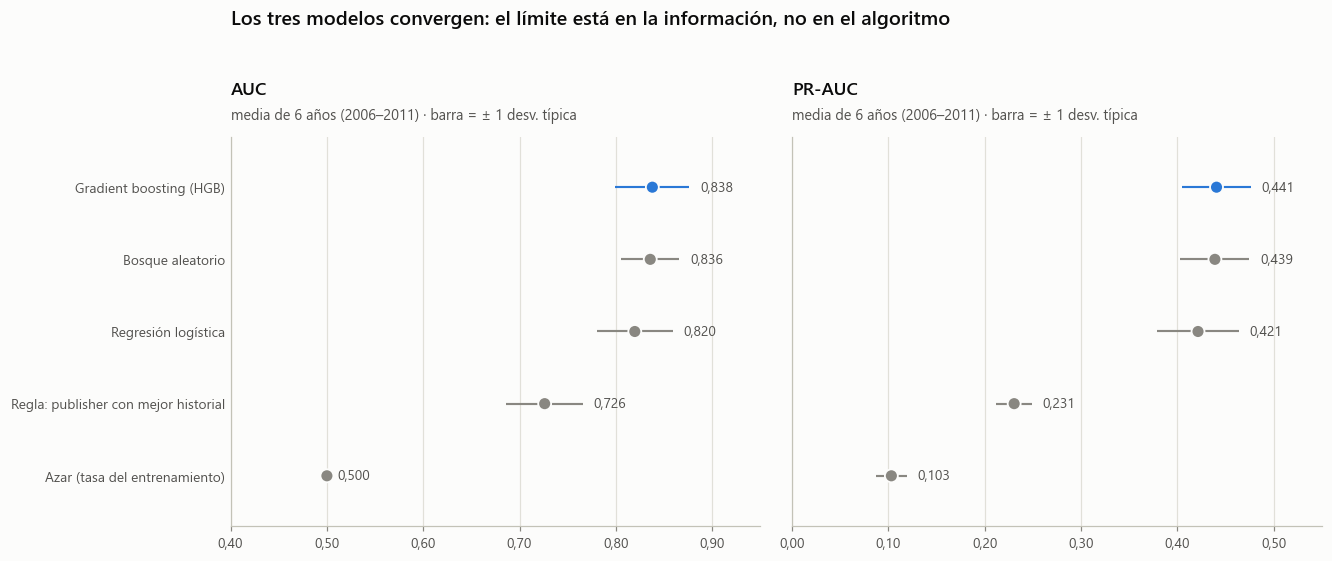

In [8]:
orden = comp.sort_values("auc").reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.6), sharey=True, gridspec_kw={"wspace": 0.06})
y = np.arange(len(orden))                      # la fila de menor AUC abajo, la de mayor arriba
colores = np.where(orden["modelo"].eq("Gradient boosting (HGB)"), estilo.AZUL, estilo.APAGADO)
for ax, col, sd, titulo, lim in [(axes[0], "auc", "auc_sd", "AUC", (0.4, 0.95)), (axes[1], "pr_auc", "pr_sd", "PR-AUC", (0.0, 0.55))]:
    ax.hlines(y, orden[col] - orden[sd], orden[col] + orden[sd], color=colores, lw=1.4, zorder=3)
    ax.scatter(orden[col], y, s=72, color=colores, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4)
    for yi, v, s in zip(y, orden[col], orden[sd]):
        ax.text(v + s + (lim[1] - lim[0]) * 0.02, yi, estilo.num(v, 3), va="center", ha="left", fontsize=9, color=estilo.TINTA_2)
    ax.set_xlim(*lim)
    ax.set_ylim(-0.7, len(orden) - 0.3)
    estilo.rejilla(ax, "x")
    ax.xaxis.set_major_formatter(estilo.formato_eje(2))
    estilo.titular(ax, titulo, "media de 6 años (2006–2011) · barra = ± 1 desv. típica")
axes[0].set_yticks(y, orden["modelo"])
for ax in axes:
    ax.tick_params(axis="y", length=0)
fig.suptitle("Los tres modelos convergen: el límite está en la información, no en el algoritmo", x=0.125, y=1.13, ha="left", fontsize=13, fontweight="600", color=estilo.TINTA)
estilo.guardar(fig, "fig15_comparacion_de_modelos.png")
plt.show()

> **Hallazgo.** Todos los modelos reales superan con claridad al azar (AUC 0,5) y a la **regla del analista** (AUC 0,726): saber «quién publica» ya da bastante, pero un modelo con plataforma, saga y ciclo de vida lo mejora en 0,11 de AUC y casi duplica su PR-AUC (0,441 frente a 0,231).
>
> Entre los tres modelos, en cambio, **casi no hay diferencias**: el *gradient boosting* (0,838), el bosque aleatorio (0,836) y la regresión logística (0,820) se solapan dentro de la variación entre años (± 0,03–0,04). Cuando algoritmos muy distintos topan con el mismo techo, el límite está en la **información disponible**, no en el algoritmo.
>
> Se elige el *gradient boosting* por tener el mejor AUC, PR-AUC y *log-loss* en la selección (criterio fijado antes de abrir la prueba final).

## 6. Ajuste fino
Una rejilla pequeña de hiperparámetros del *gradient boosting*, evaluada con **los mismos folds de selección** (no con la prueba final) y ordenada por *log-loss*, que mide la calidad de las probabilidades:

In [9]:
rejilla = [dict(max_depth=d, learning_rate=lr, min_samples_leaf=hoja) for d in (3, 5) for lr in (0.03, 0.08) for hoja in (20, 60)]
filas = []
for cfg in rejilla:
    media, _ = M.promedio_de_folds(M.recorrer_anios(base, M.hgb, CAT, NUM, SEL, **cfg))
    filas.append({**cfg, "auc": media["auc"], "pr_auc": media["pr_auc"], "log_loss": media["log_loss"]})
ajuste = pd.DataFrame(filas).sort_values("log_loss").reset_index(drop=True)
PARAMS_FINALES = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in ajuste.loc[0, ["max_depth", "learning_rate", "min_samples_leaf"]].items()}
defecto, _ = M.promedio_de_folds(M.recorrer_anios(base, M.hgb, CAT, NUM, SEL))
print(f"Parámetros elegidos: {PARAMS_FINALES}")
print(f"Log-loss de selección: {ajuste.loc[0, 'log_loss']:.4f} (configuración por defecto del módulo: {defecto['log_loss']:.4f})\n")
ajuste.round(4)

Parámetros elegidos: {'max_depth': 5, 'learning_rate': 0.03, 'min_samples_leaf': 20}
Log-loss de selección: 0.2535 (configuración por defecto del módulo: 0.2548)



,max_depth,learning_rate,min_samples_leaf,auc,pr_auc,log_loss
0,5,0.03,20,0.8396,0.4404,0.2535
1,5,0.03,60,0.8379,0.4407,0.2548
2,5,0.08,60,0.8407,0.4460,0.2554
3,3,0.08,60,0.8341,0.4375,0.2567
4,3,0.08,20,0.8332,0.4387,0.2572
5,5,0.08,20,0.8373,0.4402,0.2586
6,3,0.03,20,0.8299,0.4288,0.2597
7,3,0.03,60,0.8304,0.4247,0.2599


> **Hallazgo.** El ajuste fino **casi no cambia nada**: la mejor configuración (profundidad 5, tasa de aprendizaje 0,03, hojas de al menos 20 fichas) mejora el *log-loss* de 0,2548 a 0,2535 y el AUC en menos de 0,002. Las ocho configuraciones quedan entre 0,830 y 0,841 de AUC. Es otra señal de que el modelo está limitado por los datos y no por sus hiperparámetros.

## 7. Evaluación final: 2012–2014
Con el bloque de variables y los hiperparámetros ya fijados, se entrena **una sola vez** con 1995–2011 y se predice 2012, 2013 y 2014 (1.784 fichas). Los intervalos son *bootstrap* sobre **títulos** (no filas): remuestrear fichas sueltas ignoraría que las versiones de un mismo juego son casi gemelas.

In [10]:
ANIOS_PRUEBA = [2012, 2013, 2014]
finales = {
    "Azar": M.ajustar_y_predecir(base, M.azar, CAT, NUM, 2011, ANIOS_PRUEBA),
    "Regla del analista": M.ajustar_y_predecir(base, M.regla_del_analista, CAT, NUM, 2011, ANIOS_PRUEBA),
    "Regresión logística": M.ajustar_y_predecir(base, M.logistica, CAT, NUM, 2011, ANIOS_PRUEBA),
    "Bosque aleatorio": M.ajustar_y_predecir(base, M.bosque, CAT, NUM, 2011, ANIOS_PRUEBA),
    "Gradient boosting (HGB)": M.ajustar_y_predecir(base, M.hgb, CAT, NUM, 2011, ANIOS_PRUEBA, **PARAMS_FINALES),
}
metricas_ic = {"AUC": roc_auc_score, "PR-AUC": average_precision_score, "Precisión en el 10 % superior": lambda y, p: M.precision_en_top(y, p, 0.10)}


def con_ic(res, funcion, dec=3):
    valor = funcion(res["y"], res["p"])
    lo, hi = M.intervalo_bootstrap(res, funcion, repeticiones=1000)
    return f"{estilo.num(valor, dec)}  [{estilo.num(lo, dec)} – {estilo.num(hi, dec)}]"


tabla_final = pd.DataFrame({nombre: {m: con_ic(res, f) for m, f in metricas_ic.items()} for nombre, res in finales.items()}).T
tabla_final["Log-loss"] = [round(M.metricas(r["y"], r["p"])["log_loss"], 3) for r in finales.values()]
hgb_final = finales["Gradient boosting (HGB)"]
tasa_base = hgb_final["y"].mean()
print(f"Prueba: {len(hgb_final):,} fichas · tasa de éxito {tasa_base:.1%} (el azar da PR-AUC = {tasa_base:.3f} y precisión en el 10 % = {tasa_base:.3f})\n")
tabla_final

Prueba: 1,784 fichas · tasa de éxito 14.3% (el azar da PR-AUC = 0.143 y precisión en el 10 % = 0.143)



,AUC,PR-AUC,Precisión en el 10 % superior,Log-loss
Azar,"0,500 [0,500 – 0,500]","0,143 [0,123 – 0,166]","0,143 [0,123 – 0,166]",0.413
Regla del analista,"0,804 [0,773 – 0,834]","0,365 [0,309 – 0,430]","0,439 [0,360 – 0,523]",0.397
Regresión logística,"0,874 [0,848 – 0,898]","0,531 [0,457 – 0,604]","0,584 [0,486 – 0,663]",0.290
Bosque aleatorio,"0,852 [0,820 – 0,880]","0,527 [0,457 – 0,602]","0,584 [0,494 – 0,676]",0.301
Gradient boosting (HGB),"0,877 [0,851 – 0,902]","0,548 [0,474 – 0,629]","0,607 [0,514 – 0,698]",0.285


In [11]:
# ¿la diferencia entre modelos es real? bootstrap pareado sobre los mismos títulos
comparaciones = []
for rival in ["Regla del analista", "Regresión logística", "Bosque aleatorio"]:
    for nombre, f in list(metricas_ic.items())[:2]:
        dif, (lo, hi) = M.diferencia_bootstrap(hgb_final, finales[rival], f, repeticiones=1000)
        comparaciones.append({"HGB − rival": rival, "métrica": nombre, "diferencia": round(dif, 3), "IC 95 %": f"[{lo:+.3f}, {hi:+.3f}]",
                              "¿excluye el 0?": "sí" if (lo > 0 or hi < 0) else "no"})
pd.DataFrame(comparaciones)

,HGB − rival,métrica,diferencia,IC 95 %,¿excluye el 0?
0,Regla del analista,AUC,0.072,"[+0.039, +0.104]",sí
1,Regla del analista,PR-AUC,0.181,"[+0.104, +0.256]",sí
2,Regresión logística,AUC,0.002,"[-0.006, +0.011]",no
3,Regresión logística,PR-AUC,0.017,"[-0.016, +0.047]",no
4,Bosque aleatorio,AUC,0.025,"[+0.012, +0.039]",sí
5,Bosque aleatorio,PR-AUC,0.020,"[-0.016, +0.057]",no


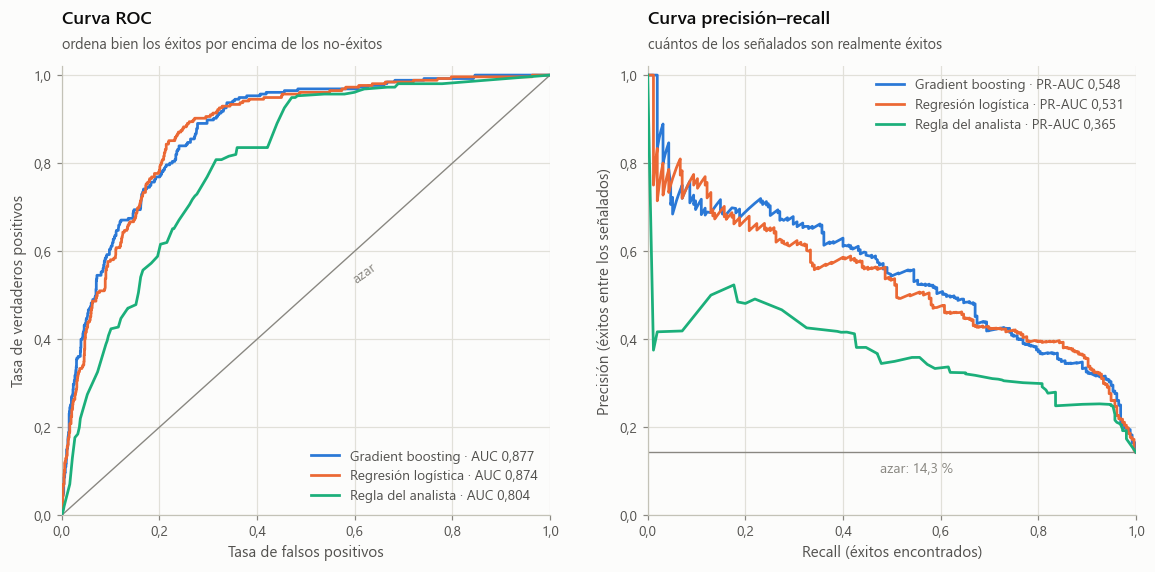

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 5.3), gridspec_kw={"wspace": 0.2})
series = [("Gradient boosting", "Gradient boosting (HGB)", estilo.AZUL), ("Regresión logística", "Regresión logística", estilo.NARANJA),
          ("Regla del analista", "Regla del analista", estilo.AQUA)]
for etiqueta, clave, color in series:
    r = finales[clave]
    fpr, tpr, _ = roc_curve(r["y"], r["p"])
    pre, rec, _ = precision_recall_curve(r["y"], r["p"])
    auc, pr = roc_auc_score(r["y"], r["p"]), average_precision_score(r["y"], r["p"])
    ax1.plot(fpr, tpr, color=color, lw=1.8, zorder=3, label=f"{etiqueta} · AUC {estilo.num(auc, 3)}")
    ax2.plot(rec, pre, color=color, lw=1.8, zorder=3, label=f"{etiqueta} · PR-AUC {estilo.num(pr, 3)}")
ax1.plot([0, 1], [0, 1], color=estilo.APAGADO, lw=0.9, zorder=2)
ax1.text(0.62, 0.55, "azar", rotation=36, color=estilo.APAGADO, fontsize=9, ha="center", va="center")
ax2.axhline(tasa_base, color=estilo.APAGADO, lw=0.9, zorder=2)
ax2.text(0.55, tasa_base - 0.045, f"azar: {estilo.pct(tasa_base * 100)}", color=estilo.APAGADO, fontsize=9, ha="center")
for ax, xl, yl, t_, s_ in [(ax1, "Tasa de falsos positivos", "Tasa de verdaderos positivos", "Curva ROC", "ordena bien los éxitos por encima de los no-éxitos"),
                           (ax2, "Recall (éxitos encontrados)", "Precisión (éxitos entre los señalados)", "Curva precisión–recall", "cuántos de los señalados son realmente éxitos")]:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    estilo.rejilla(ax, "ambos")
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.xaxis.set_major_formatter(estilo.formato_eje(1)); ax.yaxis.set_major_formatter(estilo.formato_eje(1))
    ax.legend(loc="lower right" if ax is ax1 else "upper right", frameon=False)
    estilo.titular(ax, t_, s_)
estilo.guardar(fig, "fig16_curvas_roc_y_pr.png")
plt.show()

> **Hallazgo.** En 2012–2014 (1.784 fichas, 14,3 % de éxitos) el modelo alcanza **AUC 0,877** (IC 95 % 0,851–0,902) y **PR-AUC 0,548** (0,474–0,629) frente a 0,143 del azar. El 10 % de los lanzamientos con mayor puntaje contiene un **60,7 %** de éxitos (IC 0,514–0,698), unas **4,2 veces** la tasa base.
>
> - **Frente a la regla del analista** («apostar por el publisher con mejor historial»): +0,072 de AUC (IC 0,039 a 0,104) y +0,181 de PR-AUC. La mejora es real y no es pequeña.
> - **Frente a la regresión logística:** +0,002 de AUC (IC −0,006 a +0,011): **estadísticamente indistinguibles**. Un modelo lineal y explicable rinde lo mismo, lo que sugiere que la señal es sobre todo aditiva.
> - **Frente al bosque aleatorio:** +0,025 de AUC (IC 0,012 a 0,039): ventaja real en AUC, no en PR-AUC.
>
> **No comparar a ciegas con la selección.** El AUC de la prueba (0,877) es más alto que el de los folds de selección (0,838) porque 2012–2014 son años más fáciles de ordenar: hay menos fichas y una tasa de éxito más alta (14,3 % frente a 10,3 %). El *lift* apenas cambia (4,2× frente a 4,3×). No debe leerse como que el modelo «mejoró» al verse con datos nuevos.

### La vista de negocio: ¿cuánto se gana priorizando?
Si solo se pudiera apostar por una parte de los lanzamientos, ordenados por el puntaje del modelo, ¿qué fracción de los éxitos y de las ventas se capturaría?

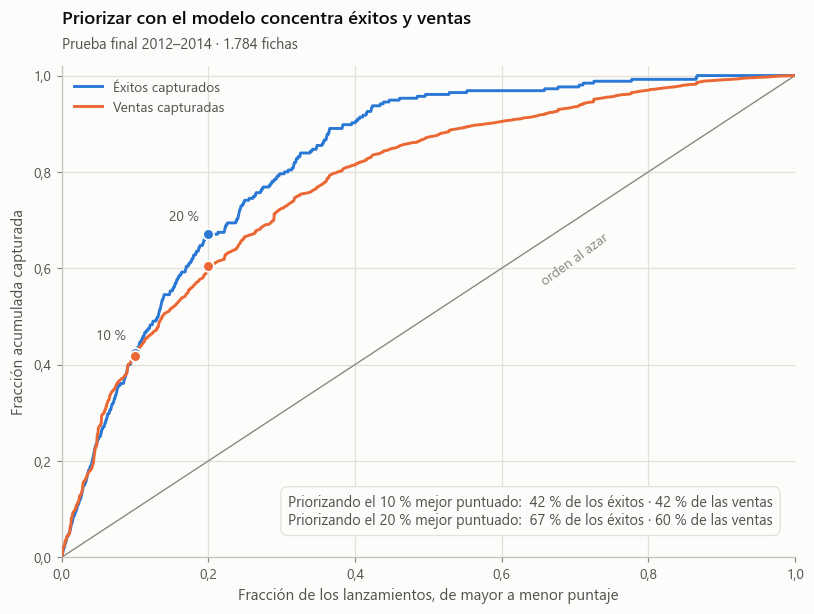

,% de los éxitos capturados,% de las ventas capturadas
% de lanzamientos priorizados,,
5,24.7,26.9
10,42.4,41.8
20,67.1,60.4
30,79.6,72.4


In [13]:
claves = ["nombre", "plataforma", "anio"]
final_df = hgb_final.merge(base[claves + ["publisher", "ventas_global", "franquicia", "fr_n_prev", "genero"]], on=claves, how="left")
assert len(final_df) == len(hgb_final)
x, gan_exitos, gan_ventas = M.curva_de_ganancia(final_df["y"], final_df["p"], final_df["ventas_global"])

fig, ax = plt.subplots(figsize=(8.6, 5.8))
ax.plot([0, 1], [0, 1], color=estilo.APAGADO, lw=0.9, zorder=2)
ax.text(0.7, 0.62, "orden al azar", rotation=36, color=estilo.APAGADO, fontsize=9, ha="center", va="center")
ax.plot(np.r_[0, x], np.r_[0, gan_exitos], color=estilo.AZUL, lw=1.9, zorder=3, label="Éxitos capturados")
ax.plot(np.r_[0, x], np.r_[0, gan_ventas], color=estilo.NARANJA, lw=1.9, zorder=3, label="Ventas capturadas")
resumen_q = []
for q in (0.10, 0.20):
    i = int(round(q * len(x))) - 1
    for v, color in ((gan_exitos[i], estilo.AZUL), (gan_ventas[i], estilo.NARANJA)):
        ax.scatter([q], [v], s=50, color=color, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=5)
    ax.annotate(f"{int(q * 100)} %", (q, max(gan_exitos[i], gan_ventas[i])), xytext=(-6, 9), textcoords="offset points", ha="right", fontsize=9, color=estilo.TINTA_2)
    resumen_q.append(f"Priorizando el {int(q * 100)} % mejor puntuado:  {estilo.pct(gan_exitos[i] * 100, 0)} de los éxitos · {estilo.pct(gan_ventas[i] * 100, 0)} de las ventas")
ax.text(0.97, 0.06, "\n".join(resumen_q), ha="right", va="bottom", fontsize=9.5, color=estilo.TINTA_2,
        bbox=dict(boxstyle="round,pad=0.5", facecolor=estilo.SUPERFICIE, edgecolor=estilo.REJILLA, linewidth=0.8))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
estilo.rejilla(ax, "ambos")
ax.xaxis.set_major_formatter(estilo.formato_eje(1)); ax.yaxis.set_major_formatter(estilo.formato_eje(1))
ax.set_xlabel("Fracción de los lanzamientos, de mayor a menor puntaje")
ax.set_ylabel("Fracción acumulada capturada")
ax.legend(loc="upper left", frameon=False)
estilo.titular(ax, "Priorizar con el modelo concentra éxitos y ventas", "Prueba final 2012–2014 · 1.784 fichas")
estilo.guardar(fig, "fig17_curva_de_ganancia.png")
plt.show()

rows = []
for q in (0.05, 0.10, 0.20, 0.30):
    i = int(round(q * len(x))) - 1
    rows.append({"% de lanzamientos priorizados": int(q * 100), "% de los éxitos capturados": round(gan_exitos[i] * 100, 1),
                 "% de las ventas capturadas": round(gan_ventas[i] * 100, 1)})
pd.DataFrame(rows).set_index("% de lanzamientos priorizados")

> **Hallazgo.** Si solo se pudiera apostar por el 10 % de los lanzamientos mejor puntuados, se captaría el **42 % de los éxitos** y el 42 % de las ventas totales; con el 20 %, el **67 %** de los éxitos y el 60 % de las ventas; con el 30 %, casi el 80 % de los éxitos. (Al azar, el 10 % captaría un 10 %.)
>
> La curva de ventas queda por debajo de la de éxitos porque algunas de las mayores ventas son sorpresas que el modelo puntuó muy bajo (p. ej. *The Last of Us*, 6,0 M, o *Minecraft* en PS4, 4,0 M; ver 9.2): el modelo ordena bien «éxito / no éxito» pero no anticipa los superéxitos inesperados.

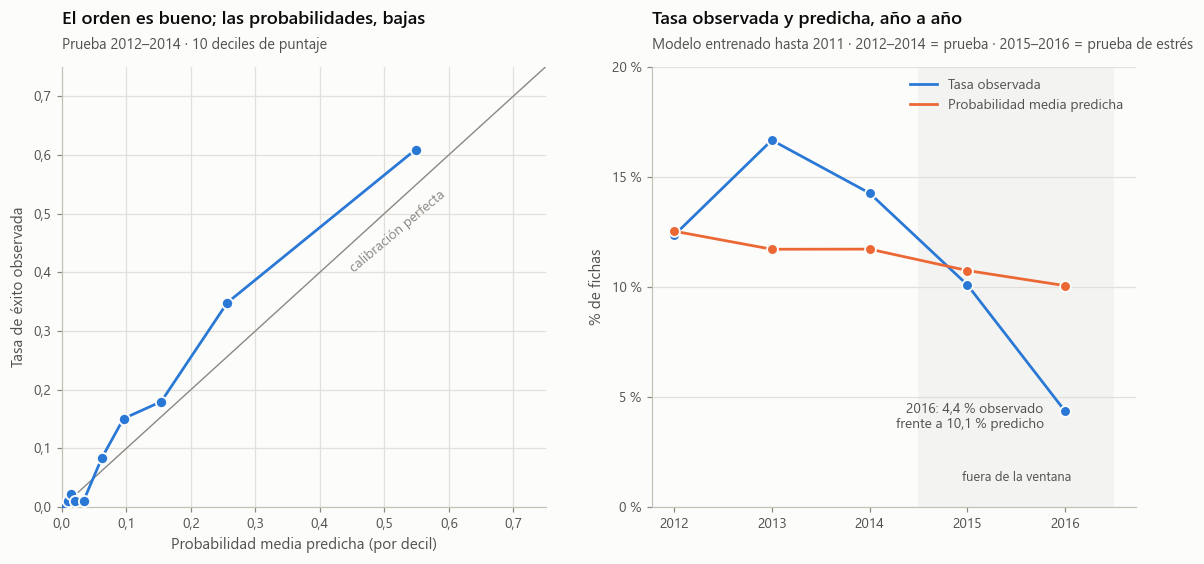

Tabla de apoyo — por año (modelo entrenado hasta 2011):


,fichas,observada,predicha,auc
anio,,,,
2012,656,12.3,12.5,0.877
2013,546,16.7,11.7,0.886
2014,582,14.3,11.7,0.871
2015,614,10.1,10.7,0.876
2016,344,4.4,10.1,0.789


In [14]:
# calibración en la prueba (deciles) y evolución año a año de la tasa observada vs la probabilidad media predicha
todos = M.ajustar_y_predecir(base, M.hgb, CAT, NUM, 2011, [2012, 2013, 2014, 2015, 2016], **PARAMS_FINALES)
cal = M.tabla_calibracion(hgb_final["y"], hgb_final["p"])
anual = todos.groupby("anio").agg(fichas=("y", "size"), observada=("y", "mean"), predicha=("p", "mean"))
anual["auc"] = todos.groupby("anio").apply(lambda g: roc_auc_score(g["y"], g["p"]), include_groups=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 5.2), gridspec_kw={"wspace": 0.22})
ax1.plot([0, 0.75], [0, 0.75], color=estilo.APAGADO, lw=0.9, zorder=2)
ax1.text(0.52, 0.47, "calibración perfecta", rotation=40, color=estilo.APAGADO, fontsize=9, ha="center", va="center")
ax1.plot(cal["predicho"], cal["observado"], color=estilo.AZUL, lw=1.8, zorder=3)
ax1.scatter(cal["predicho"], cal["observado"], s=54, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4)
ax1.set_xlim(0, 0.75); ax1.set_ylim(0, 0.75)
estilo.rejilla(ax1, "ambos")
ax1.xaxis.set_major_formatter(estilo.formato_eje(1)); ax1.yaxis.set_major_formatter(estilo.formato_eje(1))
ax1.set_xlabel("Probabilidad media predicha (por decil)"); ax1.set_ylabel("Tasa de éxito observada")
estilo.titular(ax1, "El orden es bueno; las probabilidades, bajas", "Prueba 2012–2014 · 10 deciles de puntaje")

ax2.axvspan(2014.5, 2016.5, color=estilo.GRIS_FONDO, alpha=0.16, lw=0, zorder=0)
ax2.plot(anual.index, anual["observada"] * 100, color=estilo.AZUL, lw=1.8, zorder=3, label="Tasa observada")
ax2.plot(anual.index, anual["predicha"] * 100, color=estilo.NARANJA, lw=1.8, zorder=3, label="Probabilidad media predicha")
for col, color in (("observada", estilo.AZUL), ("predicha", estilo.NARANJA)):
    ax2.scatter(anual.index, anual[col] * 100, s=50, color=color, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4)
ax2.set_xticks(anual.index)
ax2.set_ylim(0, 20)
ax2.set_yticks([0, 5, 10, 15, 20])
ax2.yaxis.set_major_formatter(estilo.formato_eje(0, " %"))
ax2.set_ylabel("% de fichas")
ax2.text(2015.5, 1.2, "fuera de la ventana", ha="center", fontsize=8.5, color=estilo.TINTA_2)
ax2.annotate(f"2016: {estilo.pct(anual.loc[2016, 'observada'] * 100)} observado\nfrente a {estilo.pct(anual.loc[2016, 'predicha'] * 100)} predicho", (2016, anual.loc[2016, "observada"] * 100),
             xytext=(-14, -4), textcoords="offset points", ha="right", va="center", fontsize=9, color=estilo.TINTA_2)
ax2.legend(loc="upper right", frameon=False, bbox_to_anchor=(1, 1.0))
estilo.titular(ax2, "Tasa observada y predicha, año a año", "Modelo entrenado hasta 2011 · 2012–2014 = prueba · 2015–2016 = prueba de estrés")
estilo.guardar(fig, "fig18_calibracion_y_prueba_de_estres.png")
plt.show()

print("Tabla de apoyo — por año (modelo entrenado hasta 2011):")
anual.assign(observada=lambda d: (d["observada"] * 100).round(1), predicha=lambda d: (d["predicha"] * 100).round(1), auc=lambda d: d["auc"].round(3))

## 8. Prueba de estrés: ¿y 2015–2016?
La ventana se fijó en 2014 por prudencia (notebook 01). El mismo modelo, sin reentrenar, permite comprobar si esa prudencia era necesaria: la tabla y el panel derecho de la figura anterior comparan, año a año, la tasa de éxito observada con la probabilidad media que predice el modelo.

> **Hallazgo.** El resultado es mixto, y por eso importa mirarlo:
>
> - **2015** se comporta como los años de prueba: AUC 0,876 y una tasa observada (10,1 %) casi igual a la probabilidad media predicha (10,7 %). La ventana se cortó en 2014 por prudencia; a la vista de esto, 2015 podría incluirse en una próxima iteración.
> - **2016 sí rompe el modelo**: el AUC baja a 0,789 y se predice un 10,1 % de éxitos cuando solo hubo un 4,4 %. Es lo esperable en un año incompleto (344 fichas) con ventas todavía sin acumular (censura por la derecha, notebook 01), y confirma que dejarlo fuera fue necesario.
>
> **Sobre la calibración en 2013–2014.** La tasa observada (16,7 % y 14,3 %) supera a la predicha (11,7 % en ambos años): la proporción de éxitos del dataset **sube** después de 2011, justo cuando cae la cobertura (quedan sobre todo los títulos notables). Por eso el modelo ordena bien cada año (AUC entre 0,87 y 0,89) pero **subestima las probabilidades** (panel izquierdo de la figura anterior). Para *priorizar* no hace falta nada más; si las probabilidades se usaran en términos absolutos (por ejemplo, para estimar cuántos éxitos habrá), habría que recalibrarlas con datos recientes.

## 9. ¿Qué usa el modelo y dónde se equivoca?

### 9.1 Importancia por grupos de variables
Se baraja un grupo entero de variables a la vez (p. ej. las cuatro de historial de franquicia) y se mide cuánto cae el AUC en la prueba 2012–2014. Barajar columnas sueltas subestimaría a las que están correlacionadas entre sí.

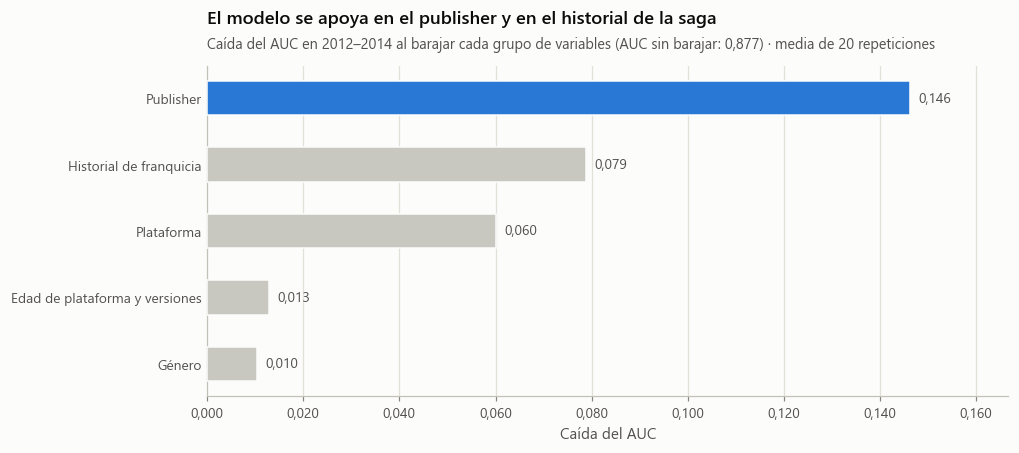

,grupo,caida_auc,desv
0,Publisher,0.1462,0.0064
1,Historial de franquicia,0.0789,0.0073
2,Plataforma,0.0602,0.0068
3,Edad de plataforma y versiones,0.0129,0.0051
4,Género,0.0103,0.0027


In [15]:
entreno = base[(base["anio"] >= M.ANIO_INICIO_ENTRENAMIENTO) & (base["anio"] <= 2011)]
prueba = base[base["anio"].isin(ANIOS_PRUEBA)]
grupos = {"Publisher": ["publisher_grp"], "Historial de franquicia": F.NUM_FRANQUICIA, "Plataforma": ["plataforma"],
          "Género": ["genero"], "Edad de plataforma y versiones": F.NUM_FICHA}
grupos = {k: [c for c in v if c in CAT + NUM] for k, v in grupos.items()}
auc_base, imp = M.importancia_por_grupo(entreno, prueba, CAT, NUM, grupos, repeticiones=20, **PARAMS_FINALES)

fig, ax = plt.subplots(figsize=(9.4, 3.9))
estilo.barras_h(ax, imp["grupo"], imp["caida_auc"], colores=[estilo.AZUL] + [estilo.GRIS_FONDO] * (len(imp) - 1), decimales=3, alto=0.52)
estilo.titular(ax, "El modelo se apoya en el publisher y en el historial de la saga",
               f"Caída del AUC en 2012–2014 al barajar cada grupo de variables (AUC sin barajar: {estilo.num(auc_base, 3)}) · media de 20 repeticiones")
ax.set_xlabel("Caída del AUC")
estilo.guardar(fig, "fig19_importancia_por_grupos.png")
plt.show()
imp.round(4)

### 9.2 Los errores más caros
Los **falsos negativos** son éxitos que el modelo puntuó muy bajo; los **falsos positivos**, no-éxitos que puntuó muy alto.

In [16]:
cols = ["nombre", "plataforma", "anio", "publisher", "ventas_global", "p", "fr_n_prev"]
print("Éxitos que el modelo casi descarta (falsos negativos):")
display(final_df[final_df["y"] == 1].nsmallest(8, "p")[cols].rename(columns={"p": "prob. predicha", "fr_n_prev": "entregas previas"}).round(3).reset_index(drop=True))
print("No-éxitos que el modelo puntuó muy alto (falsos positivos):")
display(final_df[final_df["y"] == 0].nlargest(8, "p")[cols].rename(columns={"p": "prob. predicha", "fr_n_prev": "entregas previas"}).round(3).reset_index(drop=True))

Éxitos que el modelo casi descarta (falsos negativos):


,nombre,plataforma,anio,publisher,ventas_global,prob. predicha,entregas previas
0,Yokai Watch 2 Shinuchi,3DS,2014,Level 5,2.68,0.009,0.0
1,Puzzle & Dragons,3DS,2013,GungHo,1.51,0.009,0.0
2,Guild Wars 2,PC,2012,NCSoft,2.30,0.013,3.0
3,The Last of Us,PS3,2013,Sony Computer Entertainment Europe,5.99,0.015,0.0
4,Minecraft,PSV,2014,Sony Computer Entertainment Europe,2.25,0.016,0.0
5,Knack,PS4,2013,Sony Computer Entertainment Europe,1.67,0.016,0.0
6,Minecraft,PS4,2014,Sony Computer Entertainment Europe,4.02,0.018,0.0
7,Persona 4: Golden,PSV,2012,Atlus,1.38,0.020,2.0


No-éxitos que el modelo puntuó muy alto (falsos positivos):


,nombre,plataforma,anio,publisher,ventas_global,prob. predicha,entregas previas
0,Monster Hunter Tri,WiiU,2012,Nintendo,0.72,0.886,1.0
1,Brain Age: Concentration Training,3DS,2012,Nintendo,0.09,0.869,2.0
2,Art Academy: Lessons for Everyone,3DS,2012,Nintendo,0.46,0.811,1.0
3,Infamous: First Light,PS4,2014,Sony Computer Entertainment,0.04,0.801,2.0
4,Tekken 3D: Prime Edition,3DS,2012,Nintendo,0.20,0.777,8.0
5,Epic Mickey 2: The Power of Two,PS3,2012,Disney Interactive Studios,0.50,0.748,1.0
6,Dragon Quest X,3DS,2014,Square Enix,0.17,0.714,13.0
7,Lego Batman 3: Beyond Gotham,PS3,2014,Warner Bros. Interactive Entertainment,0.81,0.692,11.0


> **Qué se ve en los errores**
>
> - **Falsos negativos: sorpresas sin historial.** Seis de los ocho éxitos más ignorados son títulos *sin* entregas previas (columna `entregas previas` = 0): *Yo-kai Watch 2*, *Puzzle & Dragons*, *The Last of Us*, *Knack* y dos versiones de *Minecraft*. Una IP nueva no deja huella en el historial, y *Minecraft* ilustra el costo del rezago: con un año de madurez exigido, las versiones de PS4 y PSV (2014) no ven la de Xbox 360 (2013).
> - **Publisher fragmentado.** *The Last of Us* (PS3), *Knack* y *Minecraft* (PS4/PSV) figuran con «Sony Computer Entertainment **Europe**», una variante regional que cae en «Otros», mientras que *The Last of Us* en PS4 figura bajo «Sony Computer Entertainment». El mismo publisher con dos etiquetas pierde su reputación. Unificar estas variantes es una mejora concreta y barata para una próxima versión.
> - **Falsos positivos: títulos menores de publishers grandes**, sobre todo en consolas portátiles de Nintendo (*Brain Age: Concentration Training*, *Art Academy*, *Tekken 3D*). El modelo confía en la reputación del publisher y de la plataforma, y estos títulos no la heredan. *Infamous: First Light* vendió solo 0,04 M en este dataset; una explicación posible es que se distribuyó sobre todo en digital, pero el dataset no permite comprobarlo.
> - **La heurística de franquicia** (notebook 01) falla en sagas que cambian de nombre por edición (*Pokémon*) y fragmenta otras (*Mario*): es una limitación conocida del historial.

### 9.3 Un ejemplo concreto: los 15 lanzamientos de 2014 mejor puntuados

In [17]:
top14 = final_df[final_df["anio"] == 2014].nlargest(15, "p")[["nombre", "plataforma", "publisher", "p", "ventas_global", "y"]].reset_index(drop=True)
top14["¿éxito?"] = np.where(top14["y"] == 1, "sí", "no")
resto14 = final_df[(final_df["anio"] == 2014) & ~final_df.index.isin(final_df[final_df["anio"] == 2014].nlargest(15, "p").index)]
print(f"De los 15 mejor puntuados de 2014, {int(top14['y'].sum())} superaron el millón ({top14['y'].mean():.0%}). "
      f"En el resto de 2014 la tasa fue del {resto14['y'].mean():.1%} ({int(resto14['y'].sum())} de {len(resto14)}).")
top14.drop(columns="y").rename(columns={"p": "prob. predicha", "ventas_global": "ventas (M)"}).round(3)

De los 15 mejor puntuados de 2014, 10 superaron el millón (67%). En el resto de 2014 la tasa fue del 12.9% (73 de 567).


,nombre,plataforma,publisher,prob. predicha,ventas (M),¿éxito?
0,Mario Kart 8,WiiU,Nintendo,0.910,6.96,sí
1,Donkey Kong Country: Tropical Freeze,WiiU,Nintendo,0.870,1.52,sí
2,inFAMOUS: Second Son,PS4,Sony Computer Entertainment,0.801,2.78,sí
3,Infamous: First Light,PS4,Sony Computer Entertainment,0.801,0.04,no
4,Grand Theft Auto V,PS4,Take-Two Interactive,0.725,11.98,sí
5,Grand Theft Auto V,XOne,Take-Two Interactive,0.725,5.08,sí
6,Dragon Quest X,3DS,Square Enix,0.714,0.17,no
7,LittleBigPlanet 3,PS4,Sony Computer Entertainment,0.709,1.86,sí
8,Lego Batman 3: Beyond Gotham,PS3,Warner Bros. Interactive Entertainment,0.692,0.81,no
9,Halo: The Master Chief Collection,XOne,Microsoft Game Studios,0.685,3.15,sí


## 10. Conclusiones, límites y próximos pasos

### Resultado en una tabla

| | |
|---|---|
| **Qué predice** | Si un lanzamiento (juego × plataforma) superará 1 M de copias |
| **Modelo** | *Gradient boosting* con 9 variables conocidas antes del lanzamiento |
| **Validación** | Walk-forward (entrena con el pasado, predice el año siguiente); prueba final 2012–2014 |
| **AUC en la prueba** | 0,877 (IC 95 % 0,851–0,902) |
| **PR-AUC** | 0,548 frente a 0,143 del azar |
| **Precisión en el 10 % mejor puntuado** | 60,7 % frente a 14,3 % (≈ 4,2×) |
| **Frente a la regla «el publisher con mejor historial»** | +0,072 de AUC (IC 95 % 0,039–0,104) |
| **Priorizando el 10 % / 20 % mejor puntuado** | 42 % / 67 % de los éxitos |

### Lo que se aprende

1. **El éxito se puede anticipar en parte, y la mayor parte de la señal está en quién publica y en la historia de la saga.** El publisher es, con diferencia, lo que más pesa (AUC −0,146 al barajarlo), seguido del historial de franquicia (−0,079) y la plataforma (−0,060). El género apenas cuenta (−0,010).
2. **La validación importa tanto como el modelo.** El mismo modelo da AUC 1,000, 0,887 o 0,853 según el protocolo. Sin walk-forward, sin agrupar por título y sin rezago de madurez, la cifra habría sido 0,034 más alta sin que el modelo valiera más.
3. **Un modelo más complejo no ayuda.** Una regresión logística rinde igual que el *gradient boosting* (diferencia de AUC +0,002, IC que incluye el 0): el techo está en la información, no en el algoritmo.
4. **Ordenar no es lo mismo que calibrar.** El modelo ordena bien cada año (AUC 0,87–0,89) pero subestima las probabilidades cuando cambia la proporción de éxitos.
5. **Hay que comparar contra alternativas simples.** Sin la «regla del analista» (AUC 0,804) no se sabría cuánto aporta realmente el modelo (+0,072).

### Límites (lo que este análisis no puede decir)

- **Cifras estimadas y cobertura cambiante.** Las ventas son estimaciones redondeadas de una web de seguimiento; no se sabe si incluyen ventas digitales y la cobertura cae tras 2011.
- **Asociación, no causalidad.** El modelo no dice que cambiar de publisher o de plataforma *cause* el éxito.
- **Variables que faltan**: presupuesto, marketing, reseñas, fecha exacta de lanzamiento, tamaño del estudio. Explican parte de las sorpresas (*Yo-kai Watch*, *Minecraft*) que ninguna ficha permite anticipar.
- **Heurística de franquicia y publishers fragmentados** (sección 9.2): el historial pierde señal en *Pokémon* o *Mario*, y las variantes regionales de un publisher no se unifican.
- **Probabilidades subestimadas tras 2011** (sección 7–8): útil para ordenar, no para estimar cuántos éxitos habrá.
- **La prueba final no es completamente «virgen».** Durante el desarrollo del proyecto, fuera de estos notebooks, se probaron variantes del diseño (rezago de 0, 1 y 2 años; con y sin el bloque del publisher) y se consultaron los resultados de 2012–2014. Las decisiones se fijaron por razones de método (no mirar al futuro; regla de +0,005 de AUC en la selección) y las diferencias entre variantes fueron menores de 0,01 de AUC en la prueba, pero en rigor la cifra final tiene un sesgo optimista leve y no medido.
- **Fichas sin año** (≈ 1,7 %) y registros parciales quedan fuera del modelado.

### Próximos pasos

1. Unificar las variantes regionales de un mismo publisher y mejorar la detección de franquicias con coincidencia aproximada (*fuzzy matching*) o un diccionario.
2. Recalibrar las probabilidades con datos recientes (regresión isotónica o Platt) si se quieren usar en valor absoluto.
3. Un modelo por región, empezando por Japón (gustos distintos, notebook 02).
4. Predecir la **magnitud** (regresión sobre log-ventas) además del umbral de 1 M.
5. Reevaluar la ventana incluyendo 2015, que la prueba de estrés sugiere que es utilizable.